## LexisNexis - Detecting Fraudulent Insurance Claims

### Mukundan Thanigaivelan

In this notebook, we train XGBoost models.

### Import libraries and data

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time, math

from xgboost import XGBClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
  accuracy_score,
  precision_score,
  recall_score,
  average_precision_score,
  f1_score,
  confusion_matrix,
  classification_report
)

In [5]:
df = pd.read_csv('Mukundan_filtered_feature_engineered_fraud_oracle.csv')
df.shape

(15420, 16)

### Prepare data

In [6]:
# Split - train on 1994, test on 1995
train = df.loc[df['Year'] == 1994, :]
test = df.loc[df['Year'] == 1995, :]

In [7]:
X_train = train.drop(columns = ['Year', 'FraudFound_P'])
y_train = train['FraudFound_P']
X_test = test.drop(columns = ['Year', 'FraudFound_P'])
y_test = test['FraudFound_P']

### Tune for best XGBoost hyperparameters

In [8]:
# Identify feature types
numeric_cols = X_train.select_dtypes(
  include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
  include=["object"]
).columns.tolist()

In [9]:
# Categorical columns: one-hot encode
categorical_pipeline = Pipeline([
  ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [10]:
# Apply the appropriate transformations
preprocessor = ColumnTransformer([
  ("numeric", "passthrough", numeric_cols),
  ("categorical", categorical_pipeline, categorical_cols)
])

In [11]:
# XGBoost pipeline
xgb_pipeline = Pipeline([
  ("preprocessor", preprocessor),
  ("classifier", XGBClassifier(
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=1
  ))
])

In [12]:
# Define the hyperparameter search space
param_dist = {
  "classifier__n_estimators": [100, 200, 300, 500, 800],
  "classifier__max_depth": [3, 4, 5, 6, 8, 10],
  "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
  "classifier__subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
  "classifier__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
  "classifier__min_child_weight": [1, 3, 5, 7, 10],
  "classifier__gamma": [0, 0.1, 0.2, 0.5, 1],
  "classifier__reg_alpha": [0, 0.01, 0.1, 1, 10],
  "classifier__reg_lambda": [0.1, 1, 5, 10, 20]
}

# Initialize the tuner
tuner = RandomizedSearchCV(
  estimator=xgb_pipeline,
  param_distributions=param_dist,
  n_iter=50,
  cv=5,
  scoring="average_precision",
  n_jobs=-1,
  random_state=42,
  verbose=1
)

# Run hyperparameter search
tuner.fit(X_train, y_train)

# Inspect results
print("Best Parameters:", tuner.best_params_)
print("Best CV Score:", tuner.best_score_)

# Evaluate the best model on the test set
best_xgb = tuner.best_estimator_

# Predict probabilities
y_pred_proba = best_xgb.predict_proba(X_test)[:, 1]

# Calculate test PR-AUC (Average Precision)
test_pr_auc = average_precision_score(
  y_test, y_pred_proba
)
print("Test PR-AUC:", test_pr_auc)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters: {'classifier__subsample': 1.0, 'classifier__reg_lambda': 5, 'classifier__reg_alpha': 0.1, 'classifier__n_estimators': 100, 'classifier__min_child_weight': 1, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.1, 'classifier__gamma': 0, 'classifier__colsample_bytree': 0.9}
Best CV Score: 0.26853615419889315
Test PR-AUC: 0.18581570166671166


### Train XGBoost Models

- Use optimal hyperparameters from tuner

In [15]:
# Combine preprocessing and logistic regression
model = Pipeline([
  ("preprocessor", preprocessor),
  ("random_forest", XGBClassifier(
    n_estimators=100,
    subsample=1,
    reg_lambda=5,
    reg_alpha=0.1,
    min_child_weight=1,
    max_depth=4,
    learning_rate=0.1,
    gamma=0,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=-1
  ))
])

In [16]:
# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [17]:
# Evaluate
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, y_prob):.4f}")

Accuracy:  0.9424
Precision: 0.5625
Recall:    0.0299
F1-score:  0.0568
PR-AUC:    0.1858


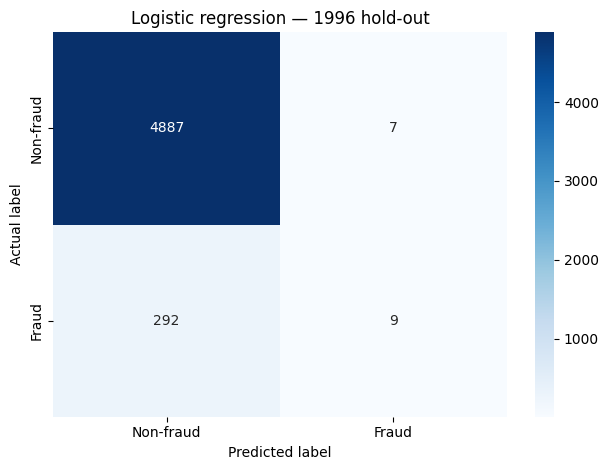

Correctly identified non-fraud: 4887
False alarms: 7
Missed fraud: 292
Fraud cases caught: 9


In [18]:
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-fraud', 'Fraud'], yticklabels=['Non-fraud', 'Fraud'])
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Logistic regression — 1996 hold-out')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = matrix.ravel()
print('Correctly identified non-fraud:', tn)
print('False alarms:', fp)
print('Missed fraud:', fn)
print('Fraud cases caught:', tp)